# Caso de estudio 1 - Olist

Analizamos nueve tablas de Olist para estudiar atrasos de entrega, calificaciones y
calidad de datos. Conservamos la fuente original y construimos una tabla con una fila
por pedido, junto con controles y pruebas con errores intencionales.

**Cómo reproducir:** desde la carpeta del proyecto, crear un entorno Python 3.12,
instalar `pip install -r requirements.txt`, ejecutar `python download_data.py`, abrir
`jupyter notebook notebook.ipynb` y elegir **Restart Kernel and Run All Cells**.
Los CSV crudos no se suben al repositorio; el manifiesto registra versión y SHA-256.


## 1. Preguntas y predicción

1. **¿Qué proporción de los pedidos entregados llegó después del día prometido y
   cómo cambia por mes de compra?** Permite ubicar períodos que merecen una revisión
   logística. La unidad es el pedido; se excluyen pedidos sin entrega confirmada o
   sin fechas suficientes y coherentes.
2. **¿La calificación media es diferente entre los pedidos entregados a tiempo y
   los entregados tarde?** Permite explorar una asociación con satisfacción, sin
   atribuir causalidad. Cada pedido pesa una vez; si tiene varias reseñas se usa su
   promedio y se conserva la cantidad de reseñas.

**Predicciones de calidad, formuladas para esta corrección antes del nuevo perfil:**

- **P1.** Habrá fechas de entrega faltantes, principalmente en pedidos no entregados.
  No toda ausencia representa un error: puede reflejar un evento que aún no ocurrió.
- **P2.** Habrá varios ítems, pagos o reseñas para algunos pedidos; unirlos directamente
  multiplicaría filas y podría inflar totales. Se espera también que un prefijo postal
  represente varias observaciones de geolocalización.

Estas predicciones no estaban en el avance original. No se afirma que el equipo las
hubiera formulado antes de aquella carga. Se contrastan con los resultados de abajo.

## 2. Entender los datos

Fuente: [Brazilian E-Commerce Public Dataset by Olist, Kaggle](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce),
versión 2. Son registros históricos de comercio electrónico de Brasil. Los períodos
exactos se calculan más adelante; no representan la actividad actual.

| Tabla | Qué representa una fila | Clave o precaución | Relación |
|---|---|---|---|
| orders | Un pedido y sus hitos | order_id | Centro del análisis |
| customers | Registro de cliente asociado a un pedido | customer_id; customer_unique_id reconoce al comprador | orders.customer_id |
| order_items | Un ítem numerado dentro del pedido | order_id + order_item_id | orders, products, sellers |
| payments | Un registro/secuencia de pago | order_id + payment_sequential | orders.order_id |
| reviews | Un registro de reseña | Verificar review_id y combinación con order_id; no asumir una reseña por pedido | orders.order_id |
| products | Un producto del catálogo | product_id | order_items.product_id |
| sellers | Un vendedor | seller_id | order_items.seller_id |
| categories | Traducción de una categoría | product_category_name | products.product_category_name |
| geolocation | Una observación de ubicación para un prefijo postal | El prefijo se repite; no es una clave única | Prefijos postales de clientes/vendedores |

`orders` se relaciona con muchos ítems, pagos y posiblemente reseñas. En la tabla
curada esas fuentes se agrupan primero por `order_id`. Productos, vendedores,
categorías y geolocalización se perfilan, pero no se necesitan para las dos preguntas.
Los importes están en reales brasileños (BRL), los pesos en gramos y las dimensiones
de productos en centímetros. Los códigos postales se leen como texto para conservar ceros.

In [1]:
from pathlib import Path
import os, json, hashlib, platform
import pandas as pd
from IPython.display import display

BASE = Path.cwd()
if not (BASE / "data").exists() and (BASE / "CasoEstudio1_Corregido").exists():
    BASE = BASE / "CasoEstudio1_Corregido"
RAW, CURATED = BASE / "data/raw", BASE / "data/curated"
RESULTS, FIGURES = BASE / "results", BASE / "figures"
for folder in [CURATED, RESULTS, FIGURES, BASE / ".mplconfig"]:
    folder.mkdir(parents=True, exist_ok=True)
os.environ["MPLCONFIGDIR"] = str(BASE / ".mplconfig")
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False})
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 100)
print("Python", platform.python_version(), "| pandas", pd.__version__,
      "| matplotlib", matplotlib.__version__)

Matplotlib is building the font cache; this may take a moment.


Python 3.12.14 | pandas 2.2.3 | matplotlib 3.11.2


In [2]:
archivos = {
    "customers": "olist_customers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "categories": "product_category_name_translation.csv",
}
faltan = [name for name in archivos.values() if not (RAW / name).exists()]
if faltan:
    raise FileNotFoundError("Ejecutar python download_data.py. Faltan: " + ", ".join(faltan))
manifest = json.loads((BASE / "data/source_manifest.json").read_text())
for record in manifest["files"]:
    digest = hashlib.sha256((RAW / record["file"]).read_bytes()).hexdigest()
    if digest != record["sha256"]:
        raise ValueError("El original fue modificado: " + record["file"])

tablas = {}
ids = ["order_id", "customer_id", "customer_unique_id", "product_id", "seller_id", "review_id"]
for nombre, archivo in archivos.items():
    columnas = pd.read_csv(RAW / archivo, nrows=0).columns
    tipos = {c: "string" for c in columnas if c in ids or "zip_code_prefix" in c}
    tablas[nombre] = pd.read_csv(RAW / archivo, dtype=tipos)

inventario = pd.DataFrame([
    {"tabla": n, "archivo": archivos[n], "formato": "CSV", "filas": len(df),
     "columnas": df.shape[1], "MB": round((RAW / archivos[n]).stat().st_size / 1e6, 3)}
    for n, df in tablas.items()
])
display(inventario)
inventario.to_csv(RESULTS / "inventario.csv", index=False)

#En esta primera etapa verificamos la existencia e integridad de los archivos originales, 
#cargamos los nueve datasets de Olist en Pandas y generamos un inventario con sus dimensiones y tamaños. 
#Esto nos permitió conocer la estructura inicial de los datos antes de comenzar con su limpieza, integración y análisis.

,tabla,archivo,formato,filas,columnas,MB
0,customers,olist_customers_dataset.csv,CSV,99441,5,9.034
1,geolocation,olist_geolocation_dataset.csv,CSV,1000163,5,61.274
2,order_items,olist_order_items_dataset.csv,CSV,112650,7,15.439
3,payments,olist_order_payments_dataset.csv,CSV,103886,5,5.777
4,reviews,olist_order_reviews_dataset.csv,CSV,99224,7,14.452
5,orders,olist_orders_dataset.csv,CSV,99441,8,17.655
6,products,olist_products_dataset.csv,CSV,32951,9,2.379
7,sellers,olist_sellers_dataset.csv,CSV,3095,4,0.175
8,categories,product_category_name_translation.csv,CSV,71,2,0.003


## 3. Explorar: tipos, faltantes, duplicados y fechas

`head()` sirve para reconocer columnas, pero no describe el conjunto completo.
Calculamos faltantes por columna, duplicados exactos por tabla y repeticiones de
claves candidatas por separado. **Duplicado exacto** significa que todas las columnas
son iguales. **Clave repetida** puede ser normal si la tabla tiene otro grano.
El perfil completo queda en `results/perfil_columnas.csv`.

In [3]:
perfil = pd.DataFrame([
    {"tabla": n, "columna": c, "tipo_original": str(df[c].dtype),
     "faltantes": int(df[c].isna().sum()), "porcentaje": round(df[c].isna().mean() * 100, 2),
     "valores_distintos": int(df[c].nunique())}
    for n, df in tablas.items() for c in df.columns
])
duplicados = pd.DataFrame([
    {"tabla": n, "filas": len(df), "duplicados_exactos": int(df.duplicated().sum())}
    for n, df in tablas.items()
])
display(perfil[perfil.faltantes > 0].sort_values("porcentaje", ascending=False))
display(duplicados)
perfil.to_csv(RESULTS / "perfil_columnas.csv", index=False)
duplicados.to_csv(RESULTS / "duplicados.csv", index=False)

,tabla,columna,tipo_original,faltantes,porcentaje,valores_distintos
25,reviews,review_comment_title,object,87656,88.34,4527
26,reviews,review_comment_message,object,58247,58.70,36159
35,orders,order_delivered_customer_date,object,2965,2.98,95664
38,products,product_category_name,object,610,1.85,73
39,products,product_name_lenght,float64,610,1.85,66
40,products,product_description_lenght,float64,610,1.85,2960
41,products,product_photos_qty,float64,610,1.85,19
34,orders,order_delivered_carrier_date,object,1783,1.79,81018
33,orders,order_approved_at,object,160,0.16,90733
42,products,product_weight_g,float64,2,0.01,2204


,tabla,filas,duplicados_exactos
0,customers,99441,0
1,geolocation,1000163,261831
2,order_items,112650,0
3,payments,103886,0
4,reviews,99224,0
5,orders,99441,0
6,products,32951,0
7,sellers,3095,0
8,categories,71,0


In [4]:
claves = {
    "orders": ["order_id"], "customers": ["customer_id"],
    "order_items": ["order_id", "order_item_id"],
    "payments": ["order_id", "payment_sequential"],
    "products": ["product_id"], "sellers": ["seller_id"],
    "categories": ["product_category_name"], "reviews": ["review_id", "order_id"],
}
pruebas_claves = []
for n, cols in claves.items():
    df = tablas[n]
    pruebas_claves.append({"tabla": n, "clave": " + ".join(cols),
                          "nulos": int(df[cols].isna().any(axis=1).sum()),
                          "repeticiones_extra": int(df.duplicated(cols).sum())})
for cols in [["review_id"]]:
    df = tablas["reviews"]
    pruebas_claves.append({"tabla": "reviews", "clave": " + ".join(cols),
                          "nulos": int(df[cols].isna().any(axis=1).sum()),
                          "repeticiones_extra": int(df.duplicated(cols).sum())})
pruebas_claves = pd.DataFrame(pruebas_claves)
display(pruebas_claves)
pruebas_claves.to_csv(RESULTS / "claves.csv", index=False)

multiplicidad = pd.DataFrame([
    {"tabla": n, "pedidos_distintos": int(tablas[n].order_id.nunique()),
     "pedidos_con_varias_filas": int((tablas[n].groupby("order_id").size() > 1).sum())}
    for n in ["order_items", "payments", "reviews"]
])
display(multiplicidad)
print("Prefijos postales distintos:", tablas["geolocation"].geolocation_zip_code_prefix.nunique())
multiplicidad.to_csv(RESULTS / "multiplicidad.csv", index=False)

,tabla,clave,nulos,repeticiones_extra
0,orders,order_id,0,0
1,customers,customer_id,0,0
2,order_items,order_id + order_item_id,0,0
3,payments,order_id + payment_sequential,0,0
4,products,product_id,0,0
5,sellers,seller_id,0,0
6,categories,product_category_name,0,0
7,reviews,review_id + order_id,0,0
8,reviews,review_id,0,814


,tabla,pedidos_distintos,pedidos_con_varias_filas
0,order_items,98666,9803
1,payments,99440,2961
2,reviews,98673,547


Prefijos postales distintos: 19015


In [5]:
# Las conversiones se hacen sobre copias: tablas y CSV originales se conservan.
orders = tablas["orders"].copy()
items = tablas["order_items"].copy()
reviews = tablas["reviews"].copy()
payments = tablas["payments"].copy()
customers = tablas["customers"].copy()
fechas = []
for n, df, cols in [
    ("orders", orders, [c for c in orders if c.endswith("_date") or c.endswith("_timestamp") or c == "order_approved_at"]),
    ("order_items", items, ["shipping_limit_date"]),
    ("reviews", reviews, ["review_creation_date", "review_answer_timestamp"]),
]:
    for c in cols:
        original = df[c]
        convertido = pd.to_datetime(original, format="%Y-%m-%d %H:%M:%S", errors="coerce")
        fechas.append({"tabla": n, "columna": c, "faltantes_originales": int(original.isna().sum()),
                       "no_interpretables": int((original.notna() & convertido.isna()).sum()),
                       "minimo": str(convertido.min()), "maximo": str(convertido.max())})
        df[c] = convertido
fechas = pd.DataFrame(fechas)
display(fechas)
fechas.to_csv(RESULTS / "fechas.csv", index=False)

faltantes_estado = orders.groupby("order_status").agg(
    pedidos=("order_id", "size"),
    sin_fecha_entrega=("order_delivered_customer_date", lambda s: s.isna().sum()),
    sin_fecha_transportista=("order_delivered_carrier_date", lambda s: s.isna().sum()),
)
faltantes_estado["porcentaje_sin_entrega"] = (100 * faltantes_estado.sin_fecha_entrega / faltantes_estado.pedidos).round(2)
display(faltantes_estado)
faltantes_estado.to_csv(RESULTS / "faltantes_por_estado.csv")


#Conclusiones de la exploracion:
#En esta etapa realizamos un análisis exploratorio de calidad de datos. 
#Identificamos valores faltantes, duplicados, verificamos las claves y analizamos la multiplicidad de los pedidos. 
#También convertimos las fechas y comprobamos que el patrón de faltantes se relacionaba con el estado de los pedidos.
#En reviews faltan muchos textos, pero las notas están disponibles. No conocemos la causa de cada ausencia.
#En productos también faltan metadatos; no podemos afirmar por qué sin más información del origen.
#En orders, muchas fechas ausentes son compatibles con el estado, aunque hay excepciones que requieren revisión.
#Los duplicados de geolocation se registraron y conservaron; esa tabla no se integra en el curado.
#Son muy pocos los datos incoherentes como por ejemplo los 8  pedidos entregados que no tienen fecha de entrega.
#encontramos que los datos tienen distintas granularidades, es decir, algunas tablas tienen una fila por pedido y otras varias.
#Por eso, no podemos unir todas las tablas directamente sin controlar la multiplicidad, porque podríamos duplicar información y obtener resultados incorrectos

,tabla,columna,faltantes_originales,no_interpretables,minimo,maximo
0,orders,order_purchase_timestamp,0,0,2016-09-04 21:15:19,2018-10-17 17:30:18
1,orders,order_approved_at,160,0,2016-09-15 12:16:38,2018-09-03 17:40:06
2,orders,order_delivered_carrier_date,1783,0,2016-10-08 10:34:01,2018-09-11 19:48:28
3,orders,order_delivered_customer_date,2965,0,2016-10-11 13:46:32,2018-10-17 13:22:46
4,orders,order_estimated_delivery_date,0,0,2016-09-30 00:00:00,2018-11-12 00:00:00
5,order_items,shipping_limit_date,0,0,2016-09-19 00:15:34,2020-04-09 22:35:08
6,reviews,review_creation_date,0,0,2016-10-02 00:00:00,2018-08-31 00:00:00
7,reviews,review_answer_timestamp,0,0,2016-10-07 18:32:28,2018-10-29 12:27:35


,pedidos,sin_fecha_entrega,sin_fecha_transportista,porcentaje_sin_entrega
order_status,,,,
approved,2,2,2,100.00
canceled,625,619,550,99.04
created,5,5,5,100.00
delivered,96478,8,2,0.01
invoiced,314,314,314,100.00
processing,301,301,301,100.00
shipped,1107,1107,0,100.00
unavailable,609,609,609,100.00


### Detalles de faltantes y reseñas

Comprobamos el patrón temporal de los títulos, los metadatos que faltan juntos en
productos y los identificadores de reseña reutilizados. Estos patrones no prueban su
causa ni que todas las opiniones sean independientes.

In [6]:
titulo_presente = reviews.review_comment_title.notna()
if titulo_presente.any():
    primer_dia_titulo = reviews.loc[titulo_presente, "review_answer_timestamp"].min().normalize()
    antes = reviews.review_answer_timestamp < primer_dia_titulo
    print("Primer día con título de reseña:", primer_dia_titulo.date())
    for nombre, mascara in [("Antes de ese día", antes), ("Desde ese día", ~antes)]:
        grupo = reviews.loc[mascara, "review_comment_title"]
        print(nombre, "| reseñas:", len(grupo), "| títulos nulos:", int(grupo.isna().sum()),
              "| porcentaje:", round(100 * grupo.isna().mean(), 2))

metadatos = ["product_category_name", "product_name_lenght",
             "product_description_lenght", "product_photos_qty"]
print("Productos sin los cuatro metadatos:",
      int(tablas["products"][metadatos].isna().all(axis=1).sum()))
print("review_id asociados a varios pedidos:",
      int((reviews.groupby("review_id").order_id.nunique() > 1).sum()))


Primer día con título de reseña: 2018-04-26
Antes de ese día | reseñas: 68782 | títulos nulos: 68782 | porcentaje: 100.0
Desde ese día | reseñas: 30442 | títulos nulos: 18874 | porcentaje: 62.0
Productos sin los cuatro metadatos: 610


review_id asociados a varios pedidos: 789


## 4. Calidad: reglas e interpretación

Reglas estrictas: claves principales sin nulos ni repeticiones, referencias obligatorias
sin huérfanos, fechas presentes que puedan interpretarse, importes no negativos y
calificaciones entre 1 y 5. Su umbral es **cero incumplimientos**, porque de otro modo
las uniones o las métricas podrían producir resultados incompatibles.

Se reportan como advertencias las ausencias en hitos, la falta de traducción de una
categoría y las secuencias temporales sospechosas. No se inventan fechas ni reseñas,
ni se elimina un pedido completo por una columna opcional faltante. Un pago de valor
cero o cuotas cero requiere interpretación; no se corrige suponiendo otro importe.

In [7]:
relaciones = [
    ("orders", "customer_id", "customers", "customer_id"),
    ("order_items", "order_id", "orders", "order_id"),
    ("order_items", "product_id", "products", "product_id"),
    ("order_items", "seller_id", "sellers", "seller_id"),
    ("payments", "order_id", "orders", "order_id"),
    ("reviews", "order_id", "orders", "order_id"),
    ("products", "product_category_name", "categories", "product_category_name"),
]
integridad = []
for hija, fk, padre, pk in relaciones:
    col = tablas[hija][fk]
    sin_match = col.notna() & ~col.isin(tablas[padre][pk])
    integridad.append({"relacion": f"{hija}.{fk} -> {padre}.{pk}",
                       "claves_nulas": int(col.isna().sum()),
                       "filas_sin_correspondencia": int(sin_match.sum())})
integridad = pd.DataFrame(integridad)
display(integridad)
integridad.to_csv(RESULTS / "integridad.csv", index=False)

calidad_numerica = pd.DataFrame([
    {"regla": "Precio negativo o nulo", "casos": int(((items.price < 0) | items.price.isna()).sum())},
    {"regla": "Flete negativo o nulo", "casos": int(((items.freight_value < 0) | items.freight_value.isna()).sum())},
    {"regla": "Pago negativo o nulo", "casos": int(((payments.payment_value < 0) | payments.payment_value.isna()).sum())},
    {"regla": "Nota fuera de 1 a 5 o nula", "casos": int((~reviews.review_score.between(1, 5)).sum())},
    {"regla": "Cuotas cero (advertencia)", "casos": int((payments.payment_installments == 0).sum())},
    {"regla": "Pago cero (advertencia)", "casos": int((payments.payment_value == 0).sum())},
])
display(calidad_numerica)
calidad_numerica.to_csv(RESULTS / "calidad_numerica.csv", index=False)

entrega_antes_compra = orders.order_delivered_customer_date < orders.order_purchase_timestamp
entrega_antes_despacho = orders.order_delivered_customer_date < orders.order_delivered_carrier_date
aprobacion_antes_compra = orders.order_approved_at < orders.order_purchase_timestamp
print("Entrega antes de compra:", int(entrega_antes_compra.sum()))
print("Entrega antes de despacho:", int(entrega_antes_despacho.sum()))
print("Aprobación antes de compra:", int(aprobacion_antes_compra.sum()))
print("Cancelados con fecha de entrega:", int((orders.order_status.eq("canceled") & orders.order_delivered_customer_date.notna()).sum()))
limites_fuera_periodo = items[items.shipping_limit_date >= pd.Timestamp("2019-01-01")]
print("Límites de despacho desde 2019 (advertencia de cobertura):", len(limites_fuera_periodo))
display(limites_fuera_periodo[["order_id", "order_item_id", "shipping_limit_date"]])

#En esta etapa establecimos reglas de calidad para verificar la integridad de las relaciones, la validez de los valores numéricos y la coherencia de las fechas. 
#Comprobamos que las relaciones obligatorias no tienen registros huérfanos y que los valores numéricos cumplen las restricciones. 
#También encontramos algunas anomalías temporales y problemas menores con categorías y pagos.
#Conservamos y señalamos estas anomalías. No conocemos su causa y no corregimos valores suponiendo promociones o errores.

,relacion,claves_nulas,filas_sin_correspondencia
0,orders.customer_id -> customers.customer_id,0,0
1,order_items.order_id -> orders.order_id,0,0
2,order_items.product_id -> products.product_id,0,0
3,order_items.seller_id -> sellers.seller_id,0,0
4,payments.order_id -> orders.order_id,0,0
5,reviews.order_id -> orders.order_id,0,0
6,products.product_category_name -> categories.p...,610,13


,regla,casos
0,Precio negativo o nulo,0
1,Flete negativo o nulo,0
2,Pago negativo o nulo,0
3,Nota fuera de 1 a 5 o nula,0
4,Cuotas cero (advertencia),2
5,Pago cero (advertencia),9


Entrega antes de compra: 0
Entrega antes de despacho: 23
Aprobación antes de compra: 0
Cancelados con fecha de entrega: 6
Límites de despacho desde 2019 (advertencia de cobertura): 4


,order_id,order_item_id,shipping_limit_date
8643,13bdf405f961a6deec817d817f5c6624,1,2020-02-05 03:30:51
68516,9c94a4ea2f7876660fa6f1b59b69c8e6,1,2020-02-03 20:23:22
85729,c2bb89b5c1dd978d507284be78a04cb2,1,2020-04-09 22:35:08
85730,c2bb89b5c1dd978d507284be78a04cb2,2,2020-04-09 22:35:08


### Primeros hallazgos y contraste de las predicciones

- **P1 se confirma con matices:** faltan 2.965 fechas de entrega (2,98% de los pedidos).
  De ellas, 2.957 corresponden a estados distintos de `delivered` y 8 a entregados.
  Se conservan todas y se excluyen del cálculo solamente los pedidos no aptos.
  Faltan títulos en 87.656 reseñas (88,34%) y mensajes en 58.247 (58,70%);
  la nota numérica sigue disponible aunque falte el texto en el CSV; no conocemos la causa de cada ausencia.
- **P2 se confirma:** 9.803 pedidos tienen varios ítems, 2.961 varios pagos y 547
  varias reseñas. Son multiplicidades de negocio. En cambio, geolocalización tiene
  261.831 duplicados exactos y su prefijo no es una clave única. Ninguna otra tabla
  tiene duplicados exactos. La pareja `review_id + order_id` sí resulta única aquí.
- Las seis relaciones obligatorias revisadas no tienen huérfanos. En productos hay
  610 categorías ausentes y 13 productos con categorías sin traducción. No se
  inventan traducciones; se trata de una limitación para un análisis por categoría.
- No se detectan fechas no interpretables ni importes negativos en los campos revisados.
  Hay 23 entregas anteriores al registro de despacho y 6 cancelados con fecha de
  entrega; se marcan para revisión. El rango de `shipping_limit_date` llega a 2020,
  fuera de la cobertura de compras de 2016-2018: se conserva y se señala, sin usarlo
  para calcular atraso de entrega al cliente.

Estos controles comprueban reglas concretas; no certifican la exactitud de todos los campos.

## 5. Integrar y curar

**Contrato de salida:** `data/curated/orders_curated.csv` contiene exactamente una
fila por `order_id` y conserva todos los pedidos. Se añaden estado del cliente (UF),
cantidades y sumas de ítems/pagos y promedio y cantidad de reseñas. Las sumas están
en BRL y la demora en días calendario. Las fechas del CSV se guardan en formato ISO.

Decisiones sencillas:

- Agrupar ítems y pagos antes de unir; usar uniones izquierdas validadas. La falta de
  registros hijos deja el importe sin dato y la cantidad en cero; no implica pago cero.
- Promediar las notas de reseñas por pedido, conservando su cantidad. No eliminar
  reseñas por repetir `order_id`. No se usan los textos en esta tabla.
- Mantener fechas faltantes como tales. Marcar si el pedido sirve para estudiar atraso:
  estado `delivered`, compra/entrega/promesa presentes y entrega y promesa no anteriores
  a la compra a nivel de día. El resto queda conservado con atraso desconocido.
- Comparar días calendario: entregar el mismo día prometido cuenta como a tiempo,
  aunque la promesa esté registrada a las 00:00. No se asigna zona horaria a la fuente.
- La geolocalización no se une: no es necesaria para estas preguntas. Sus duplicados
  se registran pero no se modifica esa fuente. Tampoco se fuerzan traducciones faltantes.
- Las secuencias de despacho sospechosas se marcan para revisión. No se cambia la
  fecha de entrega ni se supone que una anomalía pruebe cuál fecha es incorrecta.

In [8]:
# Validaciones previas: fallan explícitamente, sin corregir claves a escondidas.
if (pruebas_claves.iloc[:len(claves)][["nulos", "repeticiones_extra"]] != 0).any().any():
    raise ValueError("Revisar claves principales antes de integrar")
if (integridad.iloc[:6][["claves_nulas", "filas_sin_correspondencia"]] != 0).any().any():
    raise ValueError("Hay referencias obligatorias sin correspondencia")
if fechas.no_interpretables.sum() != 0:
    raise ValueError("Hay fechas no interpretables")
if calidad_numerica.iloc[:4].casos.sum() != 0:
    raise ValueError("Hay importes o calificaciones inválidas")

items_pedido = items.groupby("order_id", as_index=False).agg(
    n_items=("order_item_id", "size"), total_productos_brl=("price", "sum"),
    total_flete_brl=("freight_value", "sum"))
pagos_pedido = payments.groupby("order_id", as_index=False).agg(
    n_pagos=("payment_sequential", "size"), total_pagado_brl=("payment_value", "sum"))
resenas_pedido = reviews.groupby("order_id", as_index=False).agg(
    n_resenas=("review_score", "size"), nota_media=("review_score", "mean"))

curado = orders.merge(customers[["customer_id", "customer_state"]], on="customer_id",
                      how="left", validate="many_to_one")
for agregado in [items_pedido, pagos_pedido, resenas_pedido]:
    curado = curado.merge(agregado, on="order_id", how="left", validate="one_to_one")
for c in ["n_items", "n_pagos", "n_resenas"]:
    curado[c] = curado[c].fillna(0).astype("Int64")

compra = curado.order_purchase_timestamp.dt.normalize()
entrega = curado.order_delivered_customer_date.dt.normalize()
promesa = curado.order_estimated_delivery_date.dt.normalize()
curado["apto_atraso"] = (curado.order_status.eq("delivered") & compra.notna() &
                          entrega.notna() & promesa.notna() & (entrega >= compra) & (promesa >= compra))
curado["dias_respecto_promesa"] = (entrega - promesa).dt.days.where(curado.apto_atraso).astype("Int64")
curado["entrega_tarde"] = (curado.dias_respecto_promesa > 0).astype("boolean")
curado["entrega_antes_despacho"] = (curado.order_delivered_customer_date < curado.order_delivered_carrier_date)
curado["aprobacion_antes_compra"] = (curado.order_approved_at < curado.order_purchase_timestamp)
curado["cancelado_con_entrega"] = curado.order_status.eq("canceled") & curado.order_delivered_customer_date.notna()
curado["diferencia_pago_brl"] = (curado.total_pagado_brl - curado.total_productos_brl - curado.total_flete_brl).round(2)
display(curado.head(3))
for columna in ["n_items", "n_pagos", "n_resenas"]:
    print("Pedidos sin registros en", columna, ":", int(curado[columna].eq(0).sum()))


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,...,dias_respecto_promesa,entrega_tarde,entrega_antes_despacho,aprobacion_antes_compra,cancelado_con_entrega,diferencia_pago_brl
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,...,-8,False,False,False,False,0.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,...,-6,False,False,False,False,0.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,...,-18,False,False,False,False,0.0


Pedidos sin registros en n_items : 775
Pedidos sin registros en n_pagos : 1
Pedidos sin registros en n_resenas : 768


### Controles ejecutables y tres casos alterados

La función siguiente verifica el número y la identidad de los pedidos, las notas y
la coherencia del indicador de atraso. Umbral: cero incumplimientos. Prueba tres
copias con errores; ninguna modificación afecta la fuente ni la tabla que se exporta.
Estos controles detectan incompatibilidades estructurales y de rango. No prueban
que una fecha real sea correcta, que la reseña sea auténtica ni que exista causalidad.

In [9]:
def validar_curado(df, pedidos_fuente):
    if df.order_id.isna().any() or df.order_id.duplicated().any():
        raise ValueError("order_id debe ser único y no nulo")
    if len(df) != len(pedidos_fuente) or set(df.order_id) != set(pedidos_fuente.order_id):
        raise ValueError("La integración perdió o agregó pedidos")
    if not df.nota_media.dropna().between(1, 5).all():
        raise ValueError("nota_media fuera de 1 a 5")
    if not df.loc[df.apto_atraso, ["order_purchase_timestamp", "order_delivered_customer_date",
                                 "order_estimated_delivery_date", "dias_respecto_promesa", "entrega_tarde"]].notna().all().all():
        raise ValueError("Un pedido apto para atraso no tiene todas sus fechas/indicadores")
    if df.loc[~df.apto_atraso, "entrega_tarde"].notna().any():
        raise ValueError("Un pedido no apto tiene un indicador de atraso")
    compra = df.order_purchase_timestamp.dt.normalize()
    entrega = df.order_delivered_customer_date.dt.normalize()
    promesa = df.order_estimated_delivery_date.dt.normalize()
    apto_esperado = (df.order_status.eq("delivered") & compra.notna() & entrega.notna() &
                     promesa.notna() & (entrega >= compra) & (promesa >= compra))
    dias_esperados = (entrega - promesa).dt.days.where(apto_esperado).astype("Int64")
    tarde_esperado = (dias_esperados > 0).astype("boolean")
    if not df.apto_atraso.equals(apto_esperado):
        raise ValueError("Aptitud incompatible con fechas o estado")
    if not df.dias_respecto_promesa.equals(dias_esperados) or not df.entrega_tarde.equals(tarde_esperado):
        raise ValueError("Indicador de atraso incompatible con las fechas")
    for c in ["total_productos_brl", "total_flete_brl", "total_pagado_brl"]:
        if (df[c].dropna() < 0).any():
            raise ValueError("Importe negativo: " + c)
    return "OK: contrato de pedidos validado"

print(validar_curado(curado, orders))
resultados_pruebas = []
for caso in ["clave duplicada", "nota fuera de rango", "fecha apta ausente"]:
    alterado = curado.copy()
    if caso == "clave duplicada":
        alterado.loc[1, "order_id"] = alterado.loc[0, "order_id"]
    elif caso == "nota fuera de rango":
        alterado.loc[0, "nota_media"] = 9
    else:
        idx = alterado.index[alterado.apto_atraso][0]
        alterado.loc[idx, "order_delivered_customer_date"] = pd.NaT
    try:
        validar_curado(alterado, orders)
    except ValueError as error:
        resultados_pruebas.append({"caso": caso, "detectado": True, "mensaje": str(error)})
    else:
        raise RuntimeError("El control no detectó: " + caso)
resultados_pruebas = pd.DataFrame(resultados_pruebas)
display(resultados_pruebas)
resultados_pruebas.to_csv(RESULTS / "pruebas_controles.csv", index=False)

# PRUEBAS DE VALIDACIÓN:
# Introducimos 3 errores intencionales en copias del dataset:
# 1. Clave duplicada: repetimos un order_id para comprobar su unicidad.
# 2. Nota inválida: asignamos una calificación de 9 (fuera del rango 1-5).
# 3. Fecha faltante: eliminamos la fecha de entrega de un pedido apto.
#
# RESULTADO: Los 3 errores fueron detectados correctamente.
# CONCLUSIÓN: Las validaciones funcionan para estos casos y evitan
# trabajar con datos que incumplen las reglas establecidas.
# Los datos originales no fueron modificados.

OK: contrato de pedidos validado


,caso,detectado,mensaje
0,clave duplicada,True,order_id debe ser único y no nulo
1,nota fuera de rango,True,nota_media fuera de 1 a 5
2,fecha apta ausente,True,Un pedido apto para atraso no tiene todas sus ...


In [10]:
antes_despues = pd.DataFrame([
    {"indicador": "Pedidos totales", "antes": len(orders), "despues": len(curado)},
    {"indicador": "order_id repetido", "antes": int(orders.order_id.duplicated().sum()),
     "despues": int(curado.order_id.duplicated().sum())},
    {"indicador": "Sin fecha de entrega", "antes": int(orders.order_delivered_customer_date.isna().sum()),
     "despues": int(curado.order_delivered_customer_date.isna().sum())},
    {"indicador": "Columnas fecha de orders como texto", "antes": 5, "despues": 0},
])
display(antes_despues)
antes_despues.to_csv(RESULTS / "antes_despues.csv", index=False)
curado.to_csv(CURATED / "orders_curated.csv", index=False, date_format="%Y-%m-%d %H:%M:%S")

# Registro de todos los pedidos y las decisiones/ausencias observadas.
trazabilidad = curado[["order_id", "apto_atraso", "n_items", "n_pagos", "n_resenas",
                      "entrega_antes_despacho", "aprobacion_antes_compra", "cancelado_con_entrega"]].copy()
trazabilidad["entrega_faltante"] = curado.order_delivered_customer_date.isna()
trazabilidad.to_csv(RESULTS / "trazabilidad_pedidos.csv", index=False)

# Diferencia contable descriptiva: no se utiliza para alterar pagos.
comparables_pago = curado.dropna(subset=["diferencia_pago_brl"])
print("Pedidos comparables de importes:", len(comparables_pago))
print("Diferencia absoluta mayor a BRL 0,05 (tolerancia exploratoria):",
      int((comparables_pago.diferencia_pago_brl.abs() > 0.05).sum()))

,indicador,antes,despues
0,Pedidos totales,99441,99441
1,order_id repetido,0,0
2,Sin fecha de entrega,2965,2965
3,Columnas fecha de orders como texto,5,0


Pedidos comparables de importes: 98665
Diferencia absoluta mayor a BRL 0,05 (tolerancia exploratoria): 260


### Respuestas a las preguntas y gráficos

Primero fijamos el denominador. Solo usamos pedidos `apto_atraso`. La comparación
de notas también exige al menos una reseña. Los cancelados y los no entregados no
se clasifican como entregas a tiempo. El promedio de notas se calcula por pedido,
evitando que quienes tienen varias reseñas pesen más.

,pedidos,tardios,porcentaje_tarde
mes_compra,,,
2016-09,1,1,100.0
2016-10,265,2,0.75
2016-12,1,0,0.0
2017-01,750,22,2.93
2017-02,1653,49,2.96
2017-03,2546,116,4.56
2017-04,2303,151,6.56
2017-05,3545,106,2.99
2017-06,3135,95,3.03


Pedidos fuente: 99441 | entregados: 96478
Pedidos aptos: 96470 | excluidos totales: 2971
Entregados excluidos: 8
Tardíos: 6534 | porcentaje: 6.77


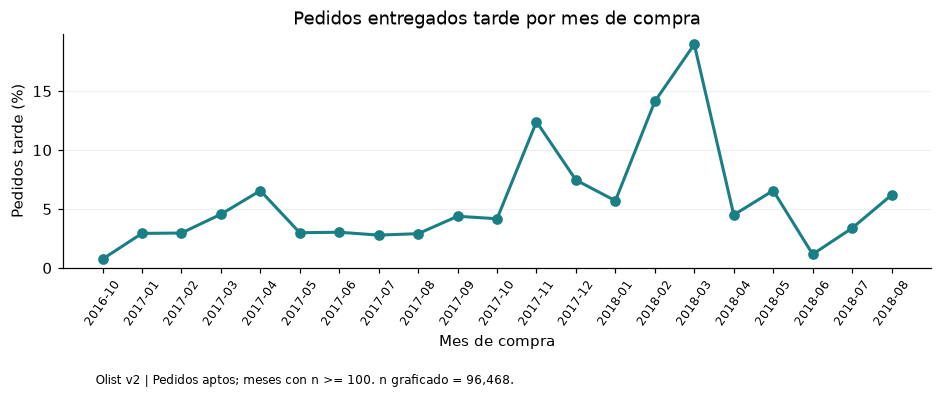

In [11]:
analisis = curado[curado.apto_atraso].copy()
analisis["mes_compra"] = analisis.order_purchase_timestamp.dt.to_period("M").astype(str)
mensual = analisis.groupby("mes_compra").agg(
    pedidos=("order_id", "size"), tardios=("entrega_tarde", "sum"))
mensual["porcentaje_tarde"] = 100 * mensual.tardios / mensual.pedidos
display(mensual.round(2))
print("Pedidos fuente:", len(curado), "| entregados:", int(curado.order_status.eq("delivered").sum()))
print("Pedidos aptos:", len(analisis), "| excluidos totales:", len(curado) - len(analisis))
print("Entregados excluidos:", int((curado.order_status.eq("delivered") & ~curado.apto_atraso).sum()))
print("Tardíos:", int(analisis.entrega_tarde.sum()), "| porcentaje:", round(100 * analisis.entrega_tarde.mean(), 2))

# Se requieren 100 pedidos por mes para evitar interpretar tasas muy inestables.
grafico_meses = mensual[mensual.pedidos >= 100]
fig, ax = plt.subplots(figsize=(8.8, 3.6))
ax.plot(grafico_meses.index, grafico_meses.porcentaje_tarde, marker="o", color="#197F85", linewidth=2)
ax.set(title="Pedidos entregados tarde por mes de compra", xlabel="Mes de compra", ylabel="Pedidos tarde (%)")
ax.tick_params(axis="x", rotation=55, labelsize=8)
ax.grid(axis="y", alpha=.2)
ax.set_ylim(bottom=0)
fig.text(.12, .015, f"Olist v2 | Pedidos aptos; meses con n >= 100. n graficado = {int(grafico_meses.pedidos.sum()):,}.", fontsize=8)
fig.tight_layout(rect=(0, .06, 1, 1))
fig.savefig(FIGURES / "atrasos_por_mes.png", dpi=180, bbox_inches="tight")
plt.show()
mensual.to_csv(RESULTS / "atrasos_por_mes.csv")

,pedidos,nota_media,mediana
entrega_tarde,,,
A tiempo,89443,4.291,5.0
Tarde,6381,2.272,1.0


Pedidos aptos sin reseña: 646


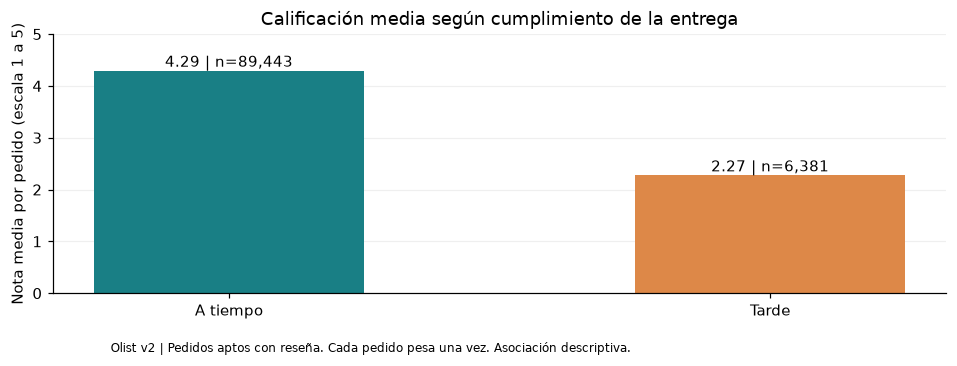

434

In [12]:
con_resena = analisis.dropna(subset=["nota_media"]).copy()
notas = con_resena.groupby("entrega_tarde").agg(
    pedidos=("order_id", "size"), nota_media=("nota_media", "mean"),
    mediana=("nota_media", "median"))
notas.index = notas.index.map({False: "A tiempo", True: "Tarde"})
display(notas.round(3))
print("Pedidos aptos sin reseña:", len(analisis) - len(con_resena))
fig, ax = plt.subplots(figsize=(8.8, 3.3))
bars = ax.bar(notas.index, notas.nota_media, color=["#197F85", "#DD8848"], width=.5)
ax.set(title="Calificación media según cumplimiento de la entrega", ylabel="Nota media por pedido (escala 1 a 5)", ylim=(0, 5))
for bar, (_, row) in zip(bars, notas.iterrows()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()+.08,
            f"{row.nota_media:.2f} | n={int(row.pedidos):,}", ha="center", fontsize=10)
ax.grid(axis="y", alpha=.2)
ax.set_axisbelow(True)
fig.text(.12, .015, "Olist v2 | Pedidos aptos con reseña. Cada pedido pesa una vez. Asociación descriptiva.", fontsize=8)
fig.tight_layout(rect=(0, .06, 1, 1))
fig.savefig(FIGURES / "notas_segun_atraso.png", dpi=180, bbox_inches="tight")
plt.show()
notas.to_csv(RESULTS / "notas_segun_atraso.csv")

resumen = {
    "pedidos": len(curado), "entregados": int(curado.order_status.eq("delivered").sum()),
    "aptos_atraso": len(analisis), "excluidos_atraso": len(curado) - len(analisis),
    "entregados_excluidos": int((curado.order_status.eq("delivered") & ~curado.apto_atraso).sum()),
    "tardios": int(analisis.entrega_tarde.sum()), "porcentaje_tarde": float(100 * analisis.entrega_tarde.mean()),
    "aptos_sin_resena": len(analisis) - len(con_resena),
    "entrega_antes_despacho": int(entrega_antes_despacho.sum()),
    "entrega_antes_compra": int(entrega_antes_compra.sum()),
    "aprobacion_antes_compra": int(aprobacion_antes_compra.sum()),
    "meses_graficados_n": int(grafico_meses.pedidos.sum()),
    "cancelado_con_entrega": int(curado.cancelado_con_entrega.sum()),
    "pago_comparables": len(comparables_pago),
    "pago_diferencia_mayor_005": int((comparables_pago.diferencia_pago_brl.abs() > 0.05).sum()),
}
(RESULTS / "resumen.json").write_text(json.dumps(resumen, indent=2), encoding="utf-8")

#En esta etapa integramos los datasets agrupando previamente los ítems, pagos y reseñas para evitar multiplicaciones de registros. 
#Construimos una tabla curada con una fila por pedido, conservando los 99.441 pedidos originales.
#Generamos el indicador apto_atraso para seleccionar los pedidos que sirven para estudiar atraso.
#Los pagos registrados en cero se conservan; un importe sin registros de pago queda como NaN. Las reseñas se promedian por pedido. 
#Finalmente, encontramos que el 6,77 % de los pedidos aptos llegó tarde y que las entregas tardías 
#tuvieron una calificación promedio de 2,27 frente a 4,29 de las entregas a tiempo.
#Los pedidos se conservan en el curado. Solo excluimos de la métrica los que no son aptos para atraso.
#Otras anomalías, como las entregas anteriores al despacho, quedan señaladas para revisión.


### Interpretación de las dos respuestas

**Pregunta 1.** De 96.470 pedidos aptos, 6.534 llegaron tarde: **6,77%**. Se excluyen
2.971 pedidos de los 99.441 originales: 2.963 no tienen estado `delivered` y 8 sí
lo tienen pero carecen de fecha real. Marzo de 2018 muestra 18,96% de atraso
(1.328 de 7.003 pedidos aptos comprados ese mes). Es una señal para revisar ese
período, no una explicación de sus causas. El gráfico solo usa meses con al menos
100 pedidos.

**Pregunta 2.** Entre los aptos con reseña, los pedidos a tiempo tienen nota media
**4,29/5** (89.443 pedidos) y los tardíos **2,27/5** (6.381 pedidos). Hay 646 pedidos
aptos sin reseña. La asociación es clara en esta muestra; no permite aislar el efecto
del atraso de otros factores ni representar a los compradores que no respondieron.

Los faltantes no se redujeron artificialmente y no se eliminaron pedidos. La mejora
está en explicitar las exclusiones y los controles. La comparación
de importes encuentra 260 pedidos con diferencia mayor a BRL 0,05 entre cobros y
precio más flete, entre 98.665 comparables. Es un diagnóstico pendiente de conciliación;
no conocemos la causa y no modificamos importes para forzar igualdad.

## 6. Cierre y uso de IA

Durante la realización del trabajo utilizamos ChatGPT como herramienta de apoyo, principalmente para ayudarnos con la estructura del código en Python, resolver dudas sobre algunas funciones de Pandas y mejorar la organización del análisis.

A partir de las ideas iniciales del grupo, fuimos consultando a la IA y adaptando las sugerencias a nuestro dataset y a los objetivos del proyecto. También la utilizamos para entender errores y pensar distintas formas de validar los datos.

Para comprobar los resultados, ejecutamos el código, revisamos las tablas y los gráficos obtenidos, y realizamos pruebas introduciendo errores intencionales para verificar que nuestros controles los detectaran.

